# Thực hành: đọc và tiền xử lý dữ liệu hoa Iris

*Bài 8, mục 8.2.1.* File `../data/iris.data` là bản gốc từ UCI Machine Learning Repository (mô tả trong `iris.names`): mỗi dòng gồm 4 số đo (cm) và tên loài, phân cách bằng dấu phẩy, **không có dòng tiêu đề**.

## 1. Đọc dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'   # notebook chạy trong codes/
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv(DATA / 'iris.data', header=None, names=columns)
print('Kích thước:', df.shape)
df.head()

Kích thước: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Kiểm tra dữ liệu

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


In [3]:
print('Số giá trị thiếu mỗi cột:')
print(df.isnull().sum())
print('Số dòng trùng lặp:', df.duplicated().sum())
print(df['species'].value_counts())

Số giá trị thiếu mỗi cột:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Số dòng trùng lặp: 1
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


Có một dòng trùng lặp (dòng 142 giống hệt dòng 101). Với Iris, hai bông hoa khác nhau hoàn toàn có thể có cùng số đo (đo chính xác tới 0.1 cm), nên ta **giữ lại**. Trong dữ liệu thực tế cần xem xét nguyên nhân trước khi xóa (Bài 2).

In [4]:
df[df.duplicated(keep=False)]

,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


## 3. Thống kê mô tả và trực quan hóa

In [5]:
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [6]:
df.groupby('species').mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.01,3.43,1.46,0.25
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


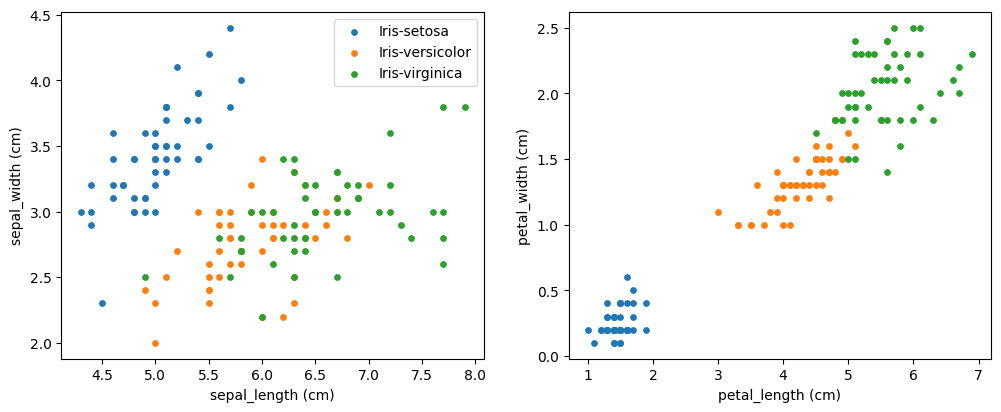

In [7]:
features = columns[:4]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, group in df.groupby('species'):
    axes[0].scatter(group['sepal_length'], group['sepal_width'], s=15, label=name)
    axes[1].scatter(group['petal_length'], group['petal_width'], s=15, label=name)
axes[0].set_xlabel('sepal_length (cm)'); axes[0].set_ylabel('sepal_width (cm)')
axes[1].set_xlabel('petal_length (cm)'); axes[1].set_ylabel('petal_width (cm)')
axes[0].legend(); plt.show()

Hai đặc trưng của cánh hoa tách nhóm setosa rất rõ; versicolor và virginica nằm sát nhau.

## 4. Bỏ nhãn: bài toán không giám sát

Phân cụm không dùng nhãn. Ta tách cột `species` ra, chỉ dùng để **đánh giá** kết quả sau khi phân cụm.

In [8]:
X = df[features].to_numpy()
species = df['species'].to_numpy()
print(X.shape)

(150, 4)


## 5. Chuẩn hóa đặc trưng

K-means dùng khoảng cách Euclid nên đặc trưng có phương sai lớn sẽ chi phối. Chuẩn hóa về trung bình 0, độ lệch chuẩn 1 bằng `StandardScaler`:

In [9]:
from sklearn.preprocessing import StandardScaler

print('Độ lệch chuẩn trước chuẩn hóa:', X.std(axis=0).round(3))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Trung bình sau chuẩn hóa     :', X_scaled.mean(axis=0).round(3) + 0.0)   # + 0.0 để không in -0.
print('Độ lệch chuẩn sau chuẩn hóa  :', X_scaled.std(axis=0).round(3))

Độ lệch chuẩn trước chuẩn hóa: [0.825 0.434 1.759 0.76 ]
Trung bình sau chuẩn hóa     : [0. 0. 0. 0.]
Độ lệch chuẩn sau chuẩn hóa  : [1. 1. 1. 1.]
